# Family Income and Expenditure Prediction

This project aims to train and test machine learning models that will enable us to predict **Monthly Household Income** and **Income Bracket Classification** given household demographic data, asset ownership, occupation, and expenditure patterns of Filipino families. The project employs several regression and classification models including Random Forest, Gradient Boosting, and Histogram-based Gradient Boosting. The models built in this project can be of help to government agencies, policy researchers, and financial institutions in making informed decisions regarding social welfare targeting, poverty classification, and economic planning.


The dataset used in this project contains information on household income, expenditure across multiple categories (food, housing, education, medical care, etc.), demographic composition, asset ownership, and occupational classification of Filipino families. Data was collected as part of the **Family Income and Expenditure Survey (FIES)** conducted by the Philippine Statistics Authority (PSA).


For more information on the dataset, columns, and data gathered, refer to the link attached:
[Family Income and Expenditure Dataset](https://www.kaggle.com/datasets/grosvenpaul/family-income-and-expenditure)

## Table of Contents

1. [Imports and Configuration](#1-imports-and-configuration)
2. [Data Loading](#2-data-loading)
3. [ISCO Occupation Mapping](#3-isco-occupation-mapping)
4. [Feature Engineering](#4-feature-engineering)
5. [Preprocessing Pipeline](#5-preprocessing-pipeline)
6. [Regression Models: Predicting Monthly Income](#6-regression-models-predicting-monthly-income)
7. [Classification Models: Predicting Income Bracket](#7-classification-models-predicting-income-bracket)
8. [Results Summary and Plots](#8-results-summary-and-plots)
9. [Conclusion](#9-conclusion)

## 1. Imports and Configuration

In [1]:
import math
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
    StackingClassifier,
    StackingRegressor,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import NuSVR

from fies_income.features import BRACKET_LABELS, engineer_features
from fies_income.modeling import (
    build_preprocessor,
    regression_metrics,
    reorder_confusion_matrix,
)
from fies_income.occupations import ISCO_MAPPING, ISCO_SKILL_LEVEL

RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = Path("data") / "Family Income and Expenditure.csv"

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

## 2. Data Loading

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

41,544 rows x 60 columns


,Total Household Income,Region,Total Food Expenditure,Main Source of Income,Agricultural Household indicator,Bread and Cereals Expenditure,Total Rice Expenditure,Meat Expenditure,Total Fish and marine products Expenditure,Fruit Expenditure,...,Number of Refrigerator/Freezer,Number of Washing Machine,Number of Airconditioner,"Number of Car, Jeep, Van",Number of Landline/wireless telephones,Number of Cellular phone,Number of Personal Computer,Number of Stove with Oven/Gas Range,Number of Motorized Banca,Number of Motorcycle/Tricycle
0,480332,CAR,117848,Wage/Salaries,0,42140,38300,24676,16806,3325,...,1,1,0,0,0,2,1,0,0,1
1,198235,CAR,67766,Wage/Salaries,0,17329,13008,17434,11073,2035,...,0,1,0,0,0,3,1,0,0,2
2,82785,CAR,61609,Wage/Salaries,1,34182,32001,7783,2590,1730,...,0,0,0,0,0,0,0,0,0,0
3,107589,CAR,78189,Wage/Salaries,0,34030,28659,10914,10812,690,...,0,0,0,0,0,1,0,0,0,0
4,189322,CAR,94625,Wage/Salaries,0,34820,30167,18391,11309,1395,...,1,0,0,0,0,3,0,0,0,1


In [3]:
display(
    pd.DataFrame(
        {
            "dtype": df.dtypes,
            "nulls": df.isna().sum(),
            "pct_null": (df.isna().mean() * 100).round(2),
        }
    )
)

,dtype,nulls,pct_null
Total Household Income,int64,0,0.00
Region,str,0,0.00
Total Food Expenditure,int64,0,0.00
Main Source of Income,str,0,0.00
Agricultural Household indicator,int64,0,0.00
Bread and Cereals Expenditure,int64,0,0.00
Total Rice Expenditure,int64,0,0.00
Meat Expenditure,int64,0,0.00
Total Fish and marine products Expenditure,int64,0,0.00
Fruit Expenditure,int64,0,0.00


In [4]:
with pd.option_context("display.max_columns", None):
    display(df.describe())

,Total Household Income,Total Food Expenditure,Agricultural Household indicator,Bread and Cereals Expenditure,Total Rice Expenditure,Meat Expenditure,Total Fish and marine products Expenditure,Fruit Expenditure,Vegetables Expenditure,Restaurant and hotels Expenditure,Alcoholic Beverages Expenditure,Tobacco Expenditure,"Clothing, Footwear and Other Wear Expenditure",Housing and water Expenditure,Imputed House Rental Value,Medical Care Expenditure,Transportation Expenditure,Communication Expenditure,Education Expenditure,Miscellaneous Goods and Services Expenditure,Special Occasions Expenditure,Crop Farming and Gardening expenses,Total Income from Entrepreneurial Acitivites,Household Head Age,Total Number of Family members,Members with age less than 5 year old,Members with age 5 - 17 years old,Total number of family members employed,House Floor Area,House Age,Number of bedrooms,Electricity,Number of Television,Number of CD/VCD/DVD,Number of Component/Stereo set,Number of Refrigerator/Freezer,Number of Washing Machine,Number of Airconditioner,"Number of Car, Jeep, Van",Number of Landline/wireless telephones,Number of Cellular phone,Number of Personal Computer,Number of Stove with Oven/Gas Range,Number of Motorized Banca,Number of Motorcycle/Tricycle
count,4.154400e+04,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,4.154400e+04,4.154400e+04,4.154400e+04,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,4.154400e+04,4.154400e+04,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000,41544.000000
mean,2.475556e+05,85099.158194,0.429858,25133.723642,18195.825005,10540.072574,10529.318337,2550.474990,5006.918568,15436.566075,1085.068121,2294.736183,4954.621076,3.837547e+04,2.092154e+04,7.160231e+03,11806.344454,4095.492057,7473.500481,12522.071635,5265.726001,1.381686e+04,5.437624e+04,51.381451,4.635182,0.410216,1.362579,1.272699,55.603360,20.125505,1.788008,0.890815,0.856875,0.435225,0.162141,0.394184,0.319806,0.129814,0.081215,0.060610,1.905738,0.315015,0.135038,0.013119,0.289885
std,2.868805e+05,51637.947682,0.676666,13466.482984,11727.224350,10497.727757,7812.201613,2969.752879,3300.175236,23705.195929,2174.431913,3998.977131,7496.500945,5.311168e+04,3.937152e+04,2.690200e+04,19351.213715,7298.822614,21219.170907,17547.027921,13279.593681,4.764378e+04,1.471428e+05,14.166081,2.280252,0.694390,1.408000,1.149152,55.023165,14.295452,1.105664,0.311875,0.646306,0.560125,0.389108,0.537025,0.478482,0.448673,0.346786,0.276732,1.558130,0.739698,0.354083,0.127171,0.558408
min,1.128500e+04,2947.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.950000e+03,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,9.000000,1.000000,0.000000,0.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.048950e+05,51017.250000,0.000000,16556.000000,11020.000000,3353.750000,5504.000000,1024.750000,2873.000000,1930.000000,0.000000,0.000000,1365.000000,1.308000e+04,6.000000e+03,3.000000e+02,2412.000000,564.000000,0.000000,3792.000000,0.000000,0.000000e+00,0.000000e+00,41.000000,3.000000,0.000000,0.000000,0.000000,25.000000,10.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
50%,1.640795e+05,72985.500000,0.000000,23324.000000,16620.000000,7332.500000,8695.000000,1820.000000,4314.000000,7314.000000,270.000000,300.000000,2740.000000,2.299200e+04,1.080000e+04,1.125000e+03,6036.000000,1506.000000,880.000000,6804.000000,1

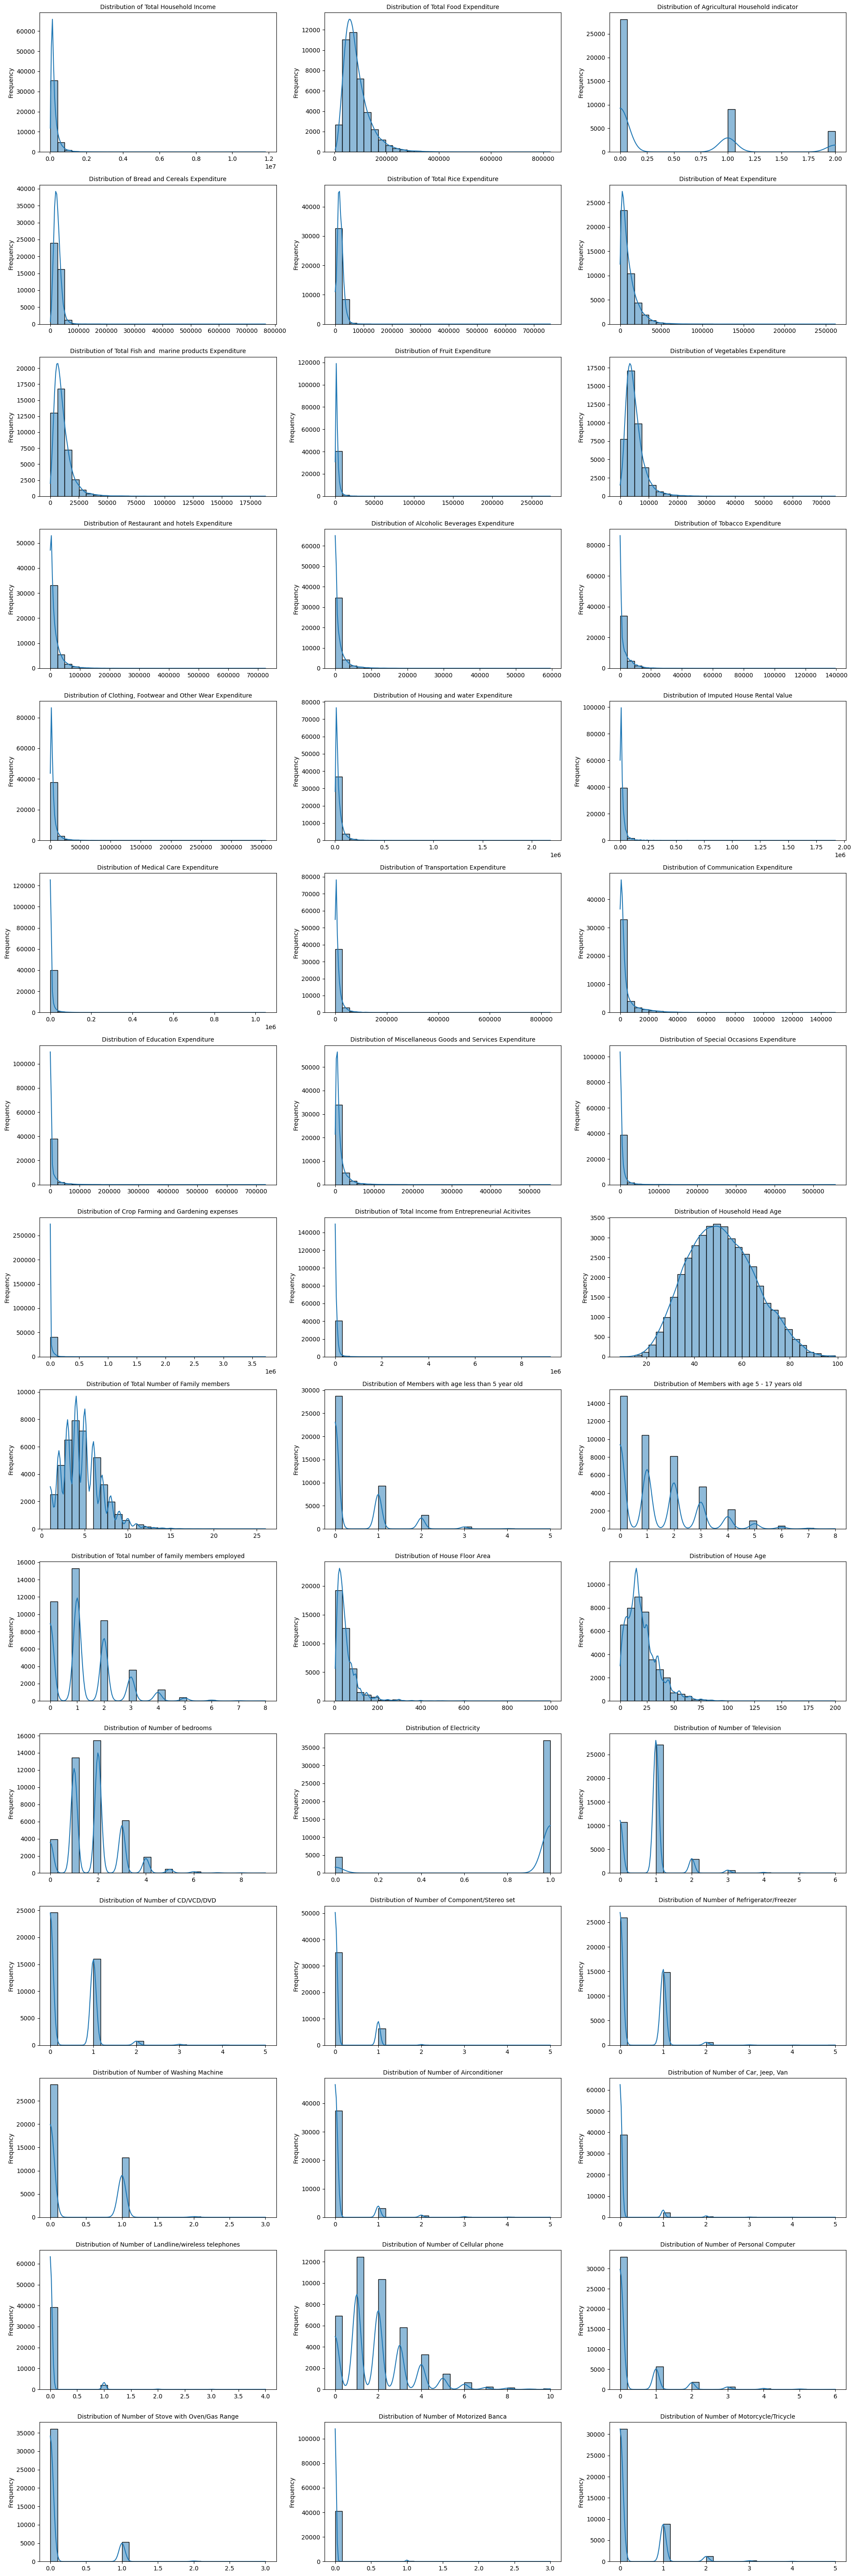

In [5]:
plot_cols = df.select_dtypes(include=["number"]).columns.tolist()

n_cols = 3
n_rows = math.ceil(len(plot_cols) / n_cols)

plt.figure(figsize=(20, n_rows * 4))
for i, col in enumerate(plot_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}", fontsize=10)
    plt.xlabel("")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

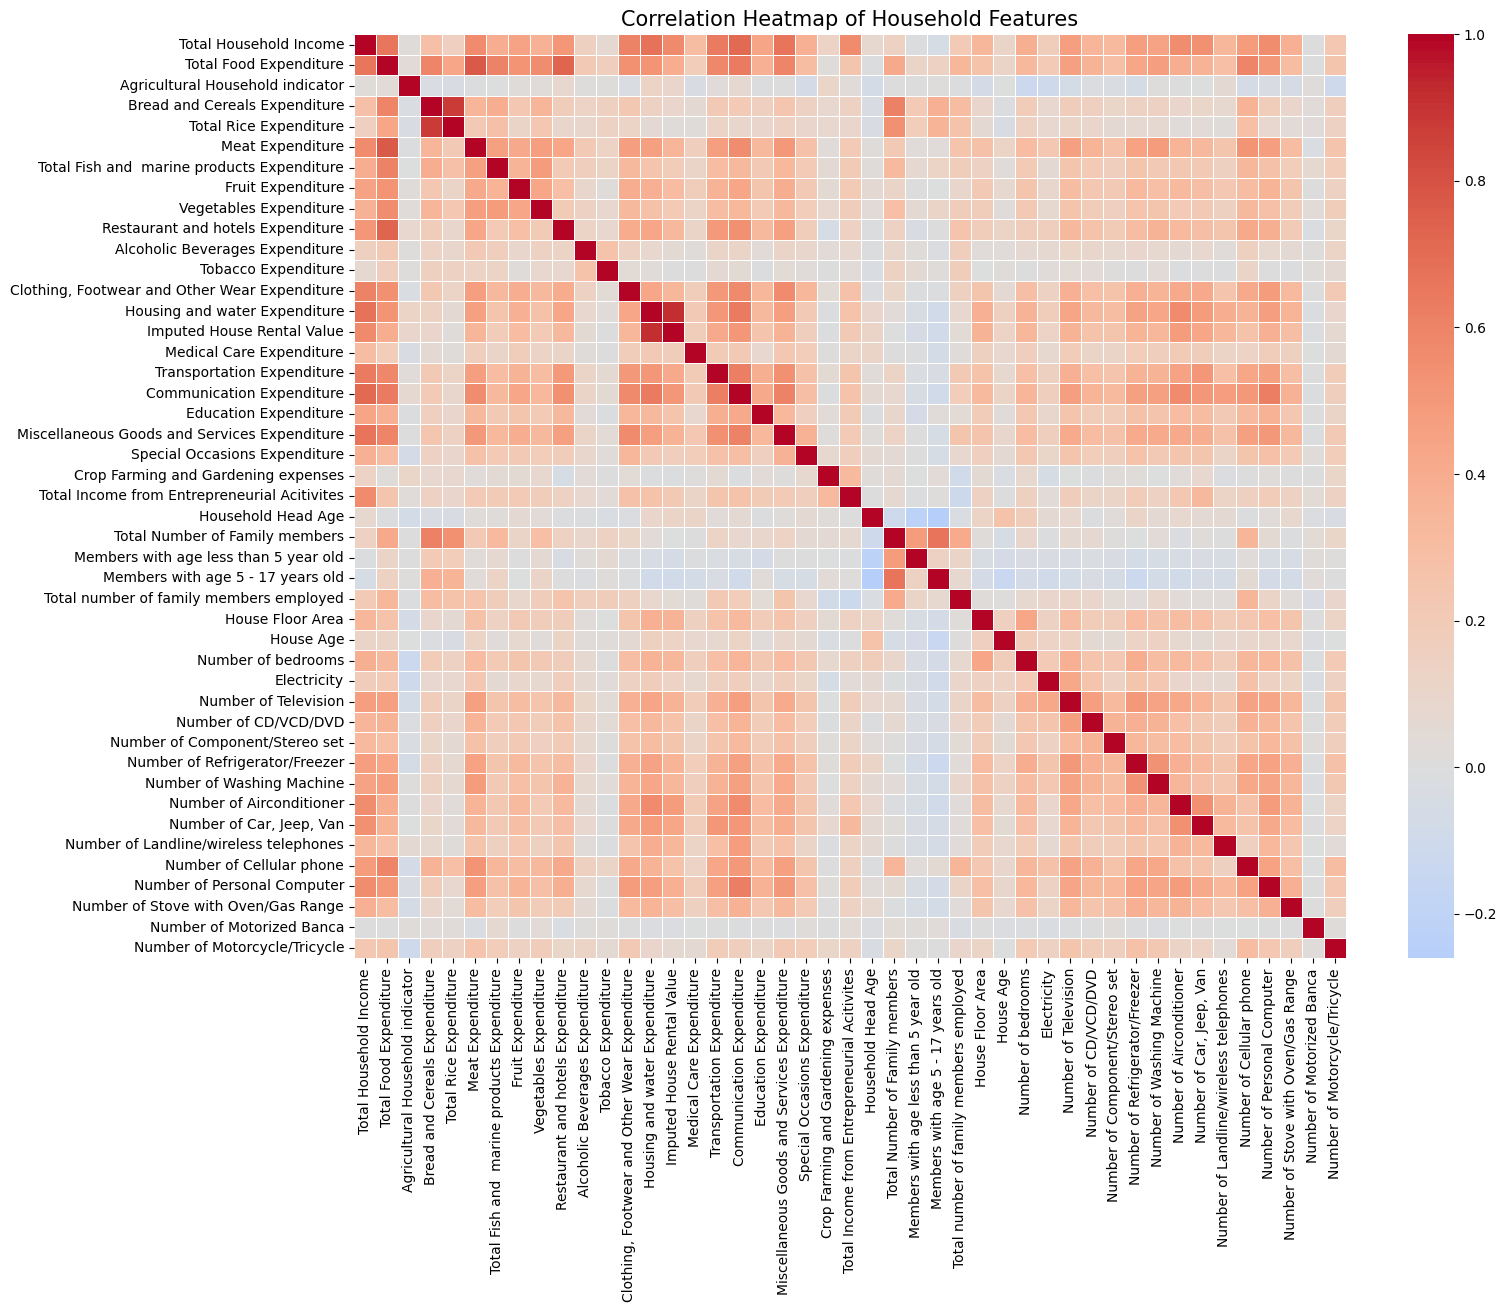

In [6]:
corr_matrix = df.select_dtypes(include=["number"]).corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Household Features", fontsize=15)
plt.show()

Based on our initial data loading and exploratory visualization, here are the key takeaways:

*   **Dataset Scale**: The dataset contains 41,544 rows and 60 columns, providing a good sample size for training machine learning models.
*   **Feature Diversity**: The features are a mix of continuous financial data (expenditures), discrete counts (number of assets like TVs or cars), and categorical demographics (Region, Occupation, Water Supply).
*   **Missing Values**: Most columns are complete, but `Toilet Facilities` and certain employment-related columns contain missing values that require imputation like `Household Head Occupation` and `Household Head Class of Worker`.
*   **Distribution Skewness**: The histograms reveal that almost all expenditure and income columns are heavily right-skewed. This is expected in economic data. Normalizing the range can help for better model convergence.
*   **Correlations**: The heatmap indicates a strong positive correlation between various expenditure types and total income. Notably, housing area and asset ownership (like Airconditioners and PCs) show higher correlations with income compared to basic food expenditures, suggesting they are strong predictors for the 'Upper Middle' and 'Rich' brackets.

## 3. ISCO Occupation Mapping

In [7]:
display(
    pd.DataFrame(
        {
            "Job Titles": {group: len(jobs) for group, jobs in ISCO_MAPPING.items()},
            "Skill Level": ISCO_SKILL_LEVEL,
        }
    )
    .rename_axis("ISCO Major Group")
    .sort_values("Skill Level", ascending=False)
)

,Job Titles,Skill Level
ISCO Major Group,,
1 - Managers,31.0,9
2 - Professionals,59.0,8
3 - Technicians and Associate Professionals,60.0,7
4 - Clerical Support Workers,19.0,6
5 - Service and Sales Workers,30.0,5
"6 - Skilled Agricultural, Forestry and Fishery Workers",32.0,4
7 - Craft and Related Trades Workers,63.0,3
"8 - Plant and Machine Operators, and Assemblers",58.0,2
9 - Elementary Occupations,20.0,1


The **International Standard Classification of Occupations (ISCO)** mapping is a step implemented in our feature engineering for several reasons:

The full title-to-group mapping and skill levels live in `fies_income/occupations.py`; the table above summarizes it.

*   **Dimensionality Reduction**: The original dataset contains hundreds of unique, specific job titles. By mapping these to the 10 major ISCO groups, we reduce noise and help the model generalize patterns across similar professions.
*   **Ordinal Skill Representation**: We've introduced an `ISCO Skill Level` feature. This transforms categorical data into a numeric hierarchy. This provides a direct ordinal signal to the regression models regarding earning potential.
*   **Handling Unemployment**: Households where the head is not working are explicitly mapped to a skill level of -1 and a group of 'Unemployed', ensuring the model can distinguish between low-skill labor and a total lack of occupational income.

## 4. Feature Engineering

In [8]:
df = engineer_features(df)

derived_cols = [
    "Monthly Income",
    "Monthly Expenditure",
    "Income Bracket",
    "ISCO Major Group",
    "ISCO Skill Level",
    "Education Years",
    "Area Per Capita",
    "People Per Bedroom",
]
display(df[derived_cols].head())

,Monthly Income,Monthly Expenditure,Income Bracket,ISCO Major Group,ISCO Skill Level,Education Years,Area Per Capita,People Per Bedroom
0,40027.666667,27252.500000,Lower Middle,2 - Professionals,8,14,20.000000,1.333333
1,16519.583333,17657.333333,Low Income,5 - Service and Sales Workers,5,14,14.000000,1.500000
2,6898.750000,8617.750000,Poor,9 - Elementary Occupations,1,3,5.833333,6.000000
3,8965.750000,11439.916667,Poor,"6 - Skilled Agricultural, Forestry and Fishery...",4,6,10.000000,3.000000
4,15776.833333,16016.833333,Low Income,1 - Managers,9,6,13.500000,1.333333


To improve model performance, we've introduced several derived features that capture socioeconomic nuances better than the raw variables alone:

*   **Monthly Normalization**: While the dataset provides annual figures, converting to monthly values aligns with standard economic reporting in the Philippines and helps in creating the income brackets.
*   **Educational Attainment**: Converting descriptive categories into `Education Years` (ordinal) allows models to treat schooling as a quantitative driver of income potential.
*   **Area Per Capita**: Total floor area is often just a reflection of family size. By dividing area by the number of members, we get a clearer signal of living standards and wealth.
*   **Housing Density**: `People Per Bedroom` acts as a proxy for overcrowding, which is a significant indicator of poverty levels.
*   **Log Transformation**: To handle the heavy right-skewness of financial data, all monetary features are log-transformed, helping the models converge more effectively.

## 5. Preprocessing Pipeline

In [9]:
TARGET_REG = "Monthly Income"
TARGET_CLF = "Income Bracket"

DETAILED_EXPENDITURES = [
    "Total Food Expenditure",
    "Bread and Cereals Expenditure",
    "Total Rice Expenditure",
    "Meat Expenditure",
    "Total Fish and  marine products Expenditure",
    "Fruit Expenditure",
    "Vegetables Expenditure",
    "Restaurant and hotels Expenditure",
    "Alcoholic Beverages Expenditure",
    "Tobacco Expenditure",
    "Clothing, Footwear and Other Wear Expenditure",
    "Housing and water Expenditure",
    "Imputed House Rental Value",
    "Medical Care Expenditure",
    "Transportation Expenditure",
    "Communication Expenditure",
    "Education Expenditure",
    "Miscellaneous Goods and Services Expenditure",
    "Special Occasions Expenditure",
    "Crop Farming and Gardening expenses",
]

SKEWED_COLS = [*DETAILED_EXPENDITURES, "Total Income from Entrepreneurial Acitivites"]

# Targets, their direct aggregates, and raw columns superseded by engineered
# features are removed to prevent leakage and redundancy.
EXCLUDE = [
    TARGET_REG,
    TARGET_CLF,
    "Annual Household Income",
    "Annual Expenditure",
    "Monthly Expenditure",
    "Household Head Highest Grade Completed",
    "Household Head Occupation",
    "ISCO Major Group",
    "House Floor Area",
    "Total Number of Family members",
    "Number of bedrooms",
]

In [10]:
feature_df = df.drop(columns=EXCLUDE)
feature_df[SKEWED_COLS] = feature_df[SKEWED_COLS].apply(np.log1p)

numeric_cols = feature_df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = feature_df.select_dtypes(
    include=["str", "category"]
).columns.tolist()
all_features = numeric_cols + categorical_cols

print(f"Total features: {len(all_features)}\n")
for col in sorted(all_features):
    print(f"- {col}")

Total features: 58

- Agricultural Household indicator
- Alcoholic Beverages Expenditure
- Area Per Capita
- Bread and Cereals Expenditure
- Clothing, Footwear and Other Wear Expenditure
- Communication Expenditure
- Crop Farming and Gardening expenses
- Education Expenditure
- Education Years
- Electricity
- Fruit Expenditure
- House Age
- Household Head Age
- Household Head Class of Worker
- Household Head Job or Business Indicator
- Household Head Marital Status
- Household Head Sex
- Housing and water Expenditure
- ISCO Skill Level
- Imputed House Rental Value
- Main Source of Income
- Main Source of Water Supply
- Meat Expenditure
- Medical Care Expenditure
- Members with age 5 - 17 years old
- Members with age less than 5 year old
- Miscellaneous Goods and Services Expenditure
- Number of Airconditioner
- Number of CD/VCD/DVD
- Number of Car, Jeep, Van
- Number of Cellular phone
- Number of Component/Stereo set
- Number of Landline/wireless telephones
- Number of Motorcycle/Tricy

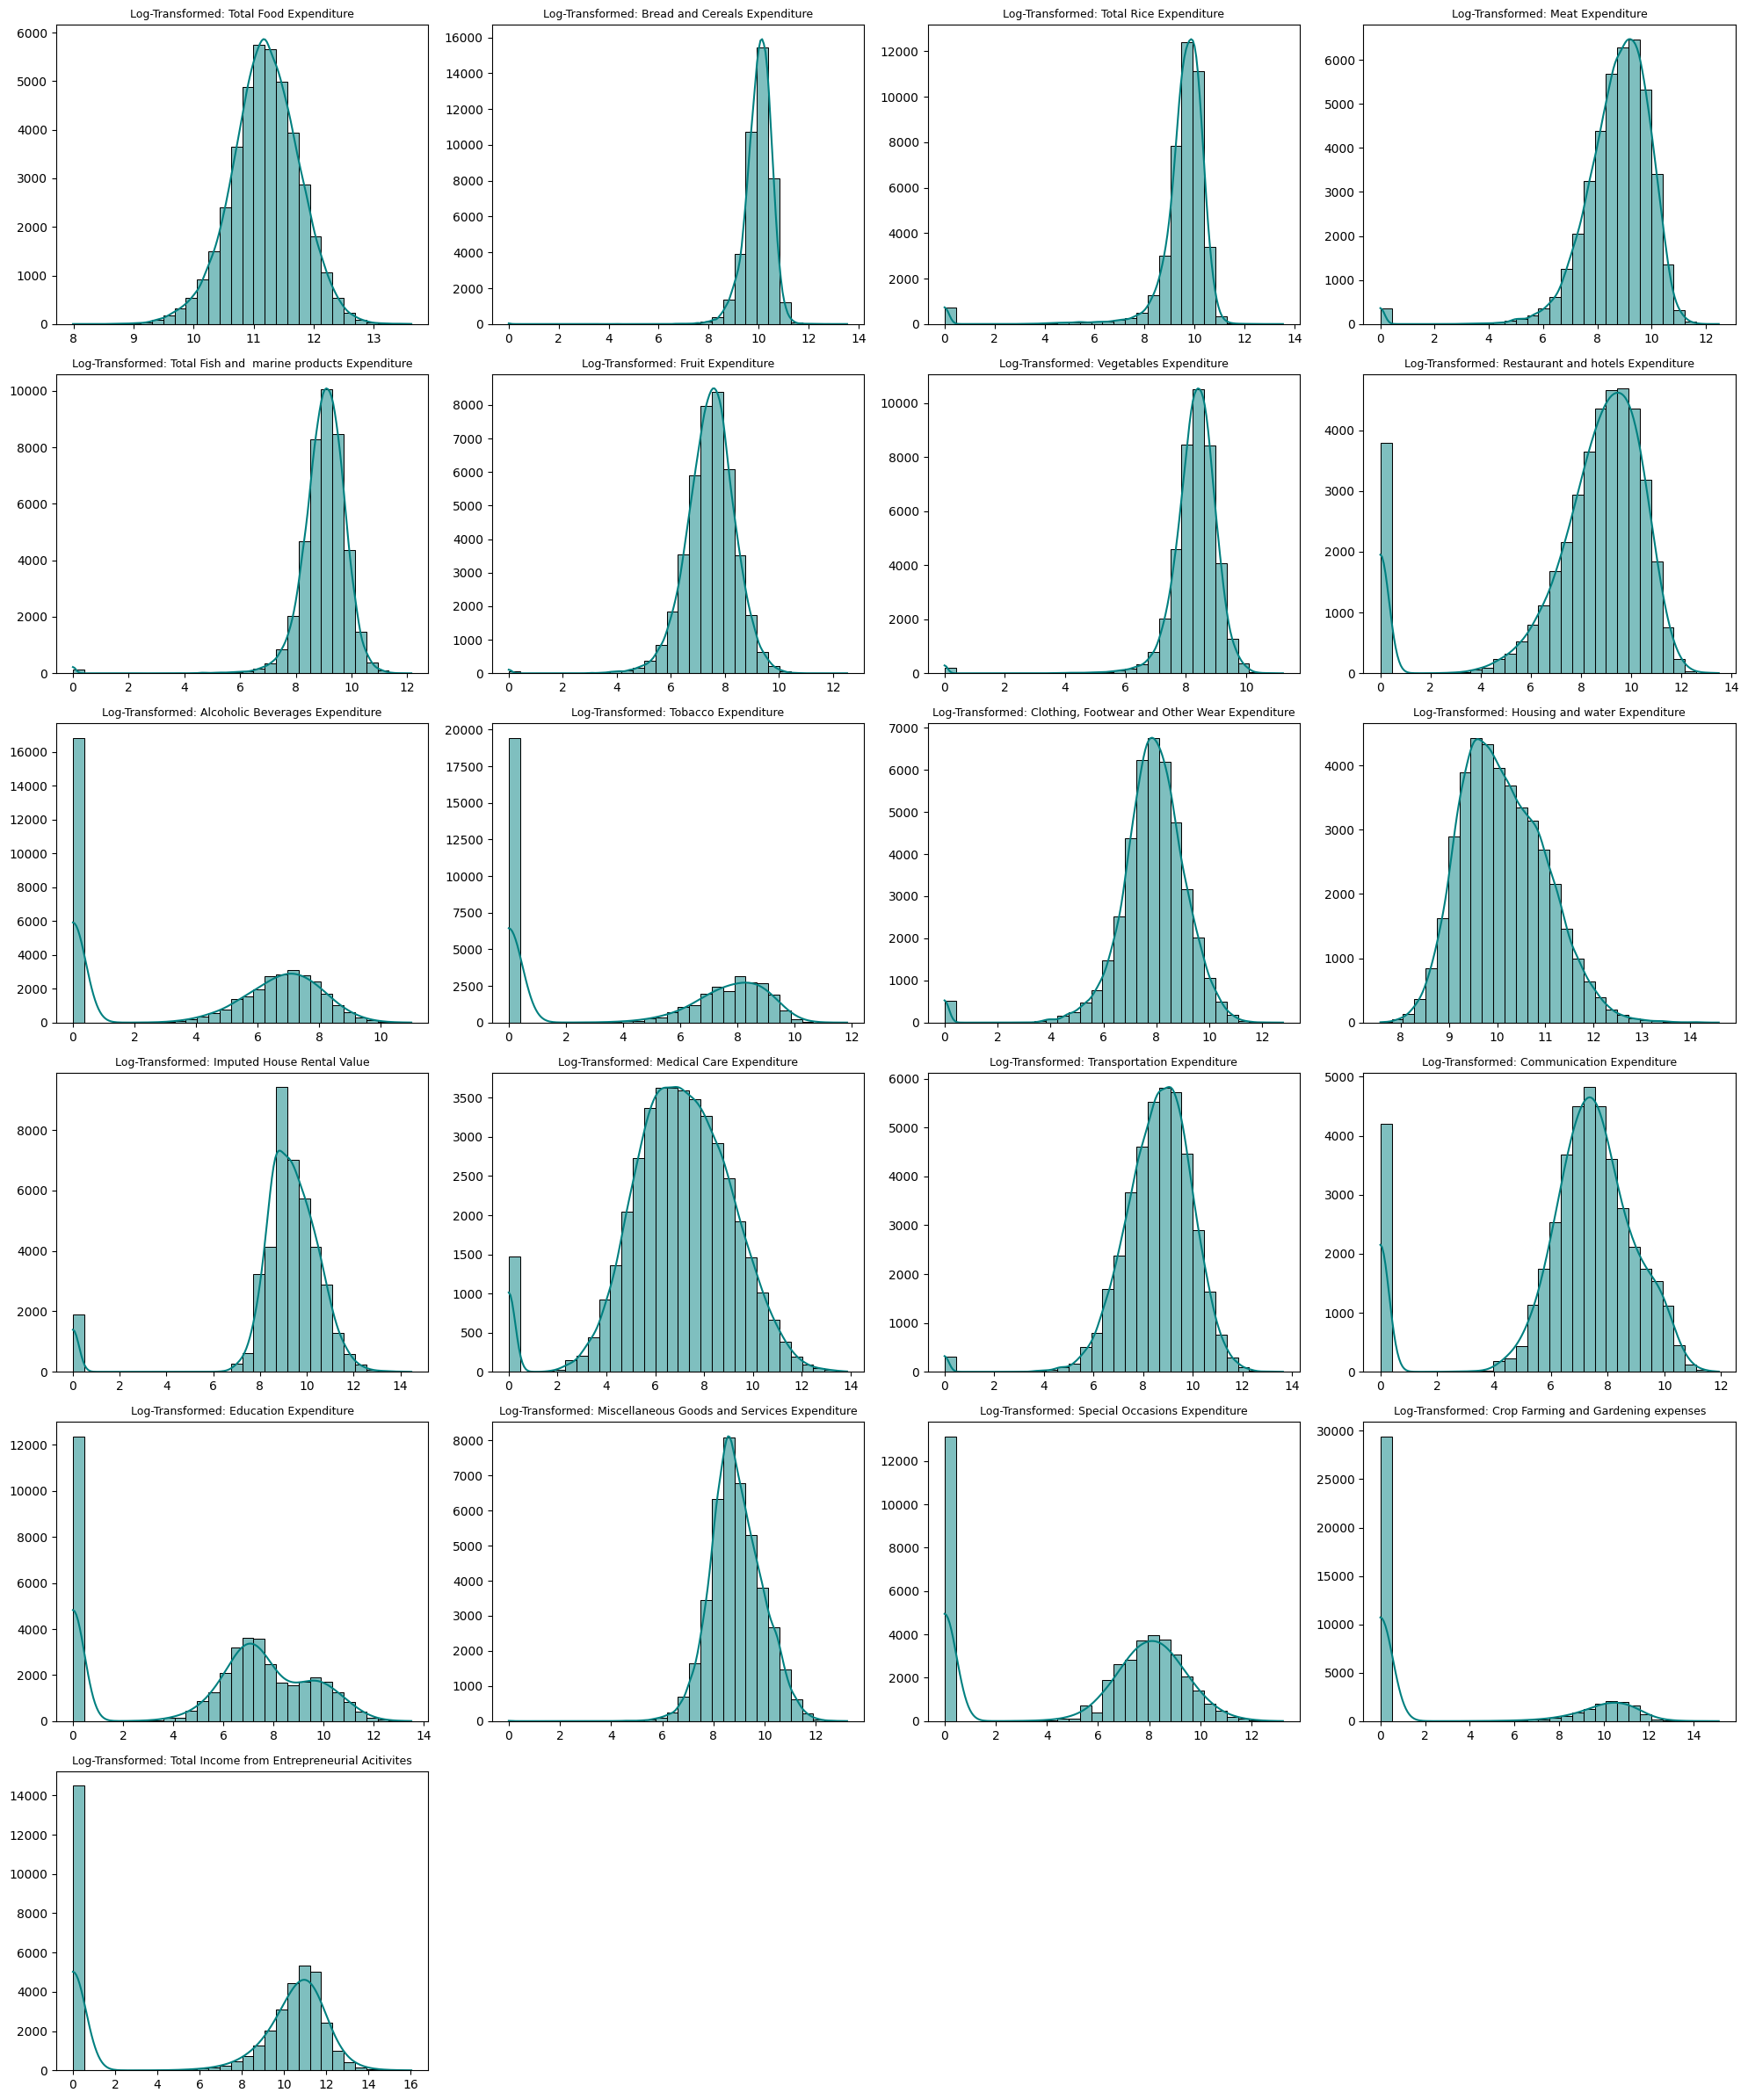

In [11]:
n_cols = 4
n_rows = math.ceil(len(SKEWED_COLS) / n_cols)

plt.figure(figsize=(20, n_rows * 4))
for i, col in enumerate(SKEWED_COLS):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(feature_df[col], kde=True, color="teal", bins=30)
    plt.title(f"Log-Transformed: {col}", fontsize=9)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()
plt.show()

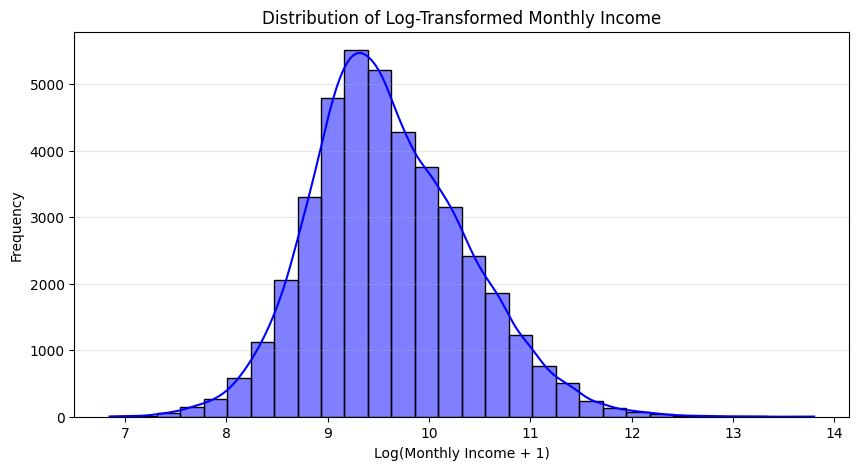

In [12]:
y_reg = np.log1p(df[TARGET_REG])
y_clf = df[TARGET_CLF].astype(str)

plt.figure(figsize=(10, 5))
sns.histplot(y_reg, kde=True, color="blue", bins=30)
plt.title("Distribution of Log-Transformed Monthly Income", fontsize=12)
plt.xlabel("Log(Monthly Income + 1)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [13]:
preprocessor = build_preprocessor(numeric_cols, categorical_cols)

# Stratify on the bracket so the rare high-income classes appear in both splits.
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    feature_df,
    y_reg,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_clf,
)
y_train_clf = y_clf.loc[X_train.index]
y_test_clf = y_clf.loc[X_test.index]

le = LabelEncoder()
y_train_clf_enc = le.fit_transform(y_train_clf)
y_test_clf_enc = le.transform(y_test_clf)

print(f"Train size: {X_train.shape[0]:,}")
print(f"Test size:  {X_test.shape[0]:,}")
print("\nIncome bracket distribution in test set (%):")
print((y_test_clf.value_counts(normalize=True) * 100).round(2))

Train size: 33,235
Test size:  8,309

Income bracket distribution in test set (%):
Income Bracket
Poor             37.73
Low Income       33.59
Lower Middle     19.69
Middle Income     6.49
Upper Middle      1.93
Upper Income      0.46
Rich              0.12
Name: proportion, dtype: float64


The preprocessing pipeline was designed to handle a diverse range of features while ensuring numerical stability for the machine learning models. Key components include:

*   **Log Transformation**: Economic data like income and expenditure often follow a power-law distribution. By applying `np.log1p` to features with high skewness, we stabilize the variance and move distributions toward normality.
    *   **Normality Check**: Our analysis shows that major predictive features like `Total Food Expenditure` and `Housing and water Expenditure` achieve a near-normal distribution after transformation. However, specific categories like `Rice` or `Vegetables` remain skewed because many households report zero or very low values, creating a lower-bound floor in the data.
*   **Imputation Strategy**:
    *   **Numeric**: We use the median to fill missing values, which is more robust to outliers than the mean in this financial dataset.
    *   **Categorical**: We use the most frequent (mode) value to ensure consistency in demographic classifications (e.g., toilet facilities).
*   **Feature Scaling**: The `StandardScaler` centers numeric data around a mean of 0 with a unit standard deviation. This is crucial for models like NuSVR, ensuring that large-magnitude features don't dominate smaller ones.
*   **One-Hot Encoding**: Categorical features (Region, Water Supply, etc.) are converted into binary flags. We use `drop='first'` to avoid multicollinearity and `handle_unknown='ignore'` to make the pipeline robust to new categories in the test set.
*   **Target Transformation**: The regression target (`Monthly Income`) is also log-transformed. This means the model predicts in log-space, and we must exponentiate results (`np.expm1`) to return to the original Philippine Peso (₱) values for evaluation. For classification, labels are encoded using `LabelEncoder` to provide numeric indices for the income brackets.

## 6. Regression Models: Predicting Monthly Income

In [14]:
reg_models = {
    "NuSVR": NuSVR(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, random_state=RANDOM_STATE
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    "Stacking Regressor": StackingRegressor(
        estimators=[
            ("nsvr", NuSVR()),
            ("hgb", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
        ],
        final_estimator=Ridge(),
        cv=5,
        n_jobs=-1,
    ),
}

In [15]:
reg_results = {}
reg_preds = {}
actual_php = np.expm1(y_test_reg.to_numpy())

for name, estimator in reg_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train_reg)

    # The model predicts log income; metrics are reported in pesos.
    pred_php = np.expm1(pipe.predict(X_test))
    reg_preds[name] = pred_php

    metrics = regression_metrics(actual_php, pred_php)
    reg_results[name] = {"Model": name, **metrics}
    print(
        f"[REG] {name:30s}  MAE=PHP {metrics['MAE']:,.0f}  "
        f"MAPE={metrics['MAPE (%)']:.1f}%  R2={metrics['R2']:.3f}  "
        f"RMSE=PHP {metrics['RMSE']:,.0f}"
    )

reg_results_df = pd.DataFrame(reg_results).T.sort_values("MAPE (%)")
display(reg_results_df)

[REG] NuSVR                           MAE=PHP 4,433  MAPE=18.8%  R2=0.613  RMSE=PHP 15,277


[REG] Random Forest                   MAE=PHP 4,027  MAPE=18.0%  R2=0.714  RMSE=PHP 13,137


[REG] Gradient Boosting               MAE=PHP 3,864  MAPE=17.2%  R2=0.741  RMSE=PHP 12,497


[REG] Hist Gradient Boosting          MAE=PHP 3,780  MAPE=16.4%  R2=0.697  RMSE=PHP 13,505


[REG] Stacking Regressor              MAE=PHP 3,778  MAPE=16.3%  R2=0.695  RMSE=PHP 13,554


,Model,MAE,MAPE (%),R2,RMSE
Stacking Regressor,Stacking Regressor,3778.257782,16.30465,0.69524,13553.703681
Hist Gradient Boosting,Hist Gradient Boosting,3780.302266,16.39307,0.697418,13505.200936
Gradient Boosting,Gradient Boosting,3863.907492,17.176469,0.740922,12496.667863
Random Forest,Random Forest,4027.380942,17.951678,0.713703,13136.734775
NuSVR,NuSVR,4432.739746,18.773128,0.612832,15276.671206


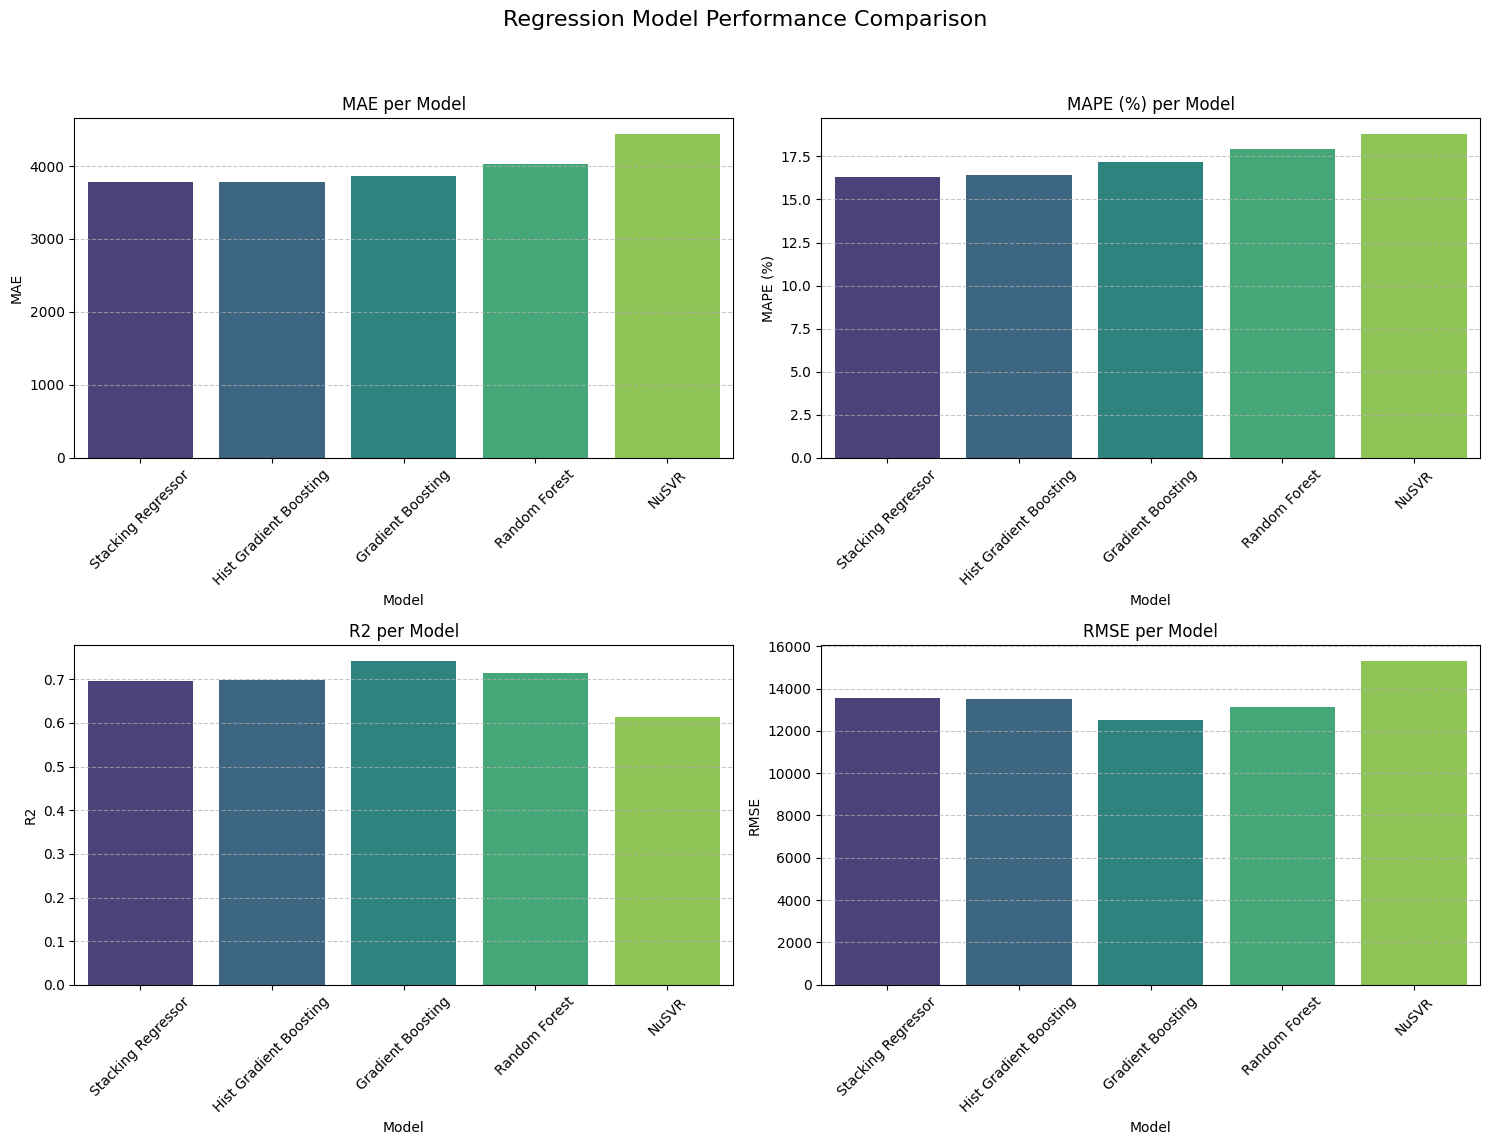

In [16]:
metric_names = ["MAE", "MAPE (%)", "R2", "RMSE"]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle("Regression Model Performance Comparison", fontsize=16)

for ax, metric in zip(axes.flatten(), metric_names, strict=True):
    sns.barplot(
        x="Model",
        y=metric,
        data=reg_results_df,
        ax=ax,
        palette="viridis",
        hue="Model",
        legend=False,
    )
    ax.set_title(f"{metric} per Model")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Comparative Analysis of Regression Models

By comparing the five models across multiple metrics, we can observe distinct patterns in how they handle the household income data using the stratified split:

*   **NuSVR**: Continues to show the highest error rates (MAE, approximately ₱4,433) and the lowest R² (approximately 0.613). While Support Vector Regressors are powerful, they are notably sensitive to the large scale and variance of this dataset compared to tree-based ensembles.
*   **Random Forest**: Provides a robust baseline with an R² of ~0.714. Its bagging approach captures non-linear relationships effectively, though it slightly lags behind the boosting methods in this specific scenario.
*   **Gradient Boosting & Hist Gradient Boosting**: Both boosting models performed exceptionally well. The **Hist Gradient Boosting Regressor** achieved a low MAPE (~16.4%), benefiting from its histogram-based binning which handles the large sample size and skewed distributions efficiently.
*   **Stacking Regressor**: By combining NuSVR and Hist Gradient Boosting, the Stacking model achieved the best overall performance with the lowest MAPE (~16.3%). This confirms that the meta-learner (Ridge) is successfully capitalizing on the different predictive strengths of the base models.
*   **Overall Trend**: All models maintain a MAPE below 19%, which is highly successful for complex socioeconomic data where unobserved factors can cause high variability in individual household spending.

## 7. Classification Models: Predicting Income Bracket

In [17]:
def ovr_logreg() -> OneVsRestClassifier:
    """Build a one-vs-rest liblinear logistic regression.

    scikit-learn 1.8 removed implicit multiclass support from the liblinear
    solver, so the one-vs-rest scheme it used to apply is made explicit.

    Returns:
        An unfitted one-vs-rest logistic regression classifier.
    """
    return OneVsRestClassifier(
        LogisticRegression(random_state=RANDOM_STATE, solver="liblinear")
    )


clf_models = {
    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting Classifier": GradientBoostingClassifier(
        n_estimators=200, random_state=RANDOM_STATE
    ),
    "Hist GBC Classifier": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "Voting Classifier": VotingClassifier(
        estimators=[
            (
                "rf",
                RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
            ),
            (
                "gb",
                GradientBoostingClassifier(n_estimators=200, random_state=RANDOM_STATE),
            ),
            ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        ],
        voting="hard",
        n_jobs=-1,
    ),
    "Stacking Classifier": StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
            ("logreg", ovr_logreg()),
        ],
        final_estimator=ovr_logreg(),
        cv=5,
        n_jobs=-1,
    ),
}

In [18]:
clf_results = {}
clf_preds = {}

for name, estimator in clf_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train_clf_enc)

    pred_enc = pipe.predict(X_test)
    clf_preds[name] = pred_enc

    print(f"\n{'=' * 60}\nModel: {name}\n{'=' * 60}")
    print(
        classification_report(
            y_test_clf_enc, pred_enc, target_names=le.classes_, zero_division=0
        )
    )

    clf_results[name] = {
        "Model": name,
        "Accuracy": accuracy_score(y_test_clf_enc, pred_enc),
        "F1 Macro": f1_score(
            y_test_clf_enc, pred_enc, average="macro", zero_division=0
        ),
    }

clf_results_df = pd.DataFrame(clf_results).T.sort_values("F1 Macro", ascending=False)
display(clf_results_df)


Model: Random Forest Classifier
               precision    recall  f1-score   support

   Low Income       0.73      0.77      0.75      2791
 Lower Middle       0.69      0.71      0.70      1636
Middle Income       0.63      0.48      0.55       539
         Poor       0.87      0.88      0.88      3135
         Rich       0.00      0.00      0.00        10
 Upper Income       0.50      0.05      0.10        38
 Upper Middle       0.54      0.28      0.37       160

     accuracy                           0.77      8309
    macro avg       0.57      0.45      0.48      8309
 weighted avg       0.76      0.77      0.76      8309




Model: Gradient Boosting Classifier
               precision    recall  f1-score   support

   Low Income       0.77      0.78      0.77      2791
 Lower Middle       0.74      0.73      0.73      1636
Middle Income       0.65      0.59      0.62       539
         Poor       0.87      0.90      0.88      3135
         Rich       1.00      0.20      0.33        10
 Upper Income       0.41      0.37      0.39        38
 Upper Middle       0.61      0.42      0.50       160

     accuracy                           0.79      8309
    macro avg       0.72      0.57      0.60      8309
 weighted avg       0.79      0.79      0.79      8309




Model: Hist GBC Classifier
               precision    recall  f1-score   support

   Low Income       0.74      0.77      0.75      2791
 Lower Middle       0.71      0.70      0.70      1636
Middle Income       0.65      0.49      0.56       539
         Poor       0.86      0.89      0.87      3135
         Rich       0.05      0.20      0.08        10
 Upper Income       0.38      0.39      0.38        38
 Upper Middle       0.55      0.32      0.40       160

     accuracy                           0.77      8309
    macro avg       0.56      0.54      0.54      8309
 weighted avg       0.77      0.77      0.77      8309




Model: Voting Classifier
               precision    recall  f1-score   support

   Low Income       0.75      0.78      0.76      2791
 Lower Middle       0.72      0.72      0.72      1636
Middle Income       0.65      0.55      0.59       539
         Poor       0.87      0.89      0.88      3135
         Rich       0.00      0.00      0.00        10
 Upper Income       0.46      0.16      0.24        38
 Upper Middle       0.62      0.36      0.45       160

     accuracy                           0.78      8309
    macro avg       0.58      0.49      0.52      8309
 weighted avg       0.78      0.78      0.78      8309




Model: Stacking Classifier
               precision    recall  f1-score   support

   Low Income       0.74      0.76      0.75      2791
 Lower Middle       0.70      0.71      0.71      1636
Middle Income       0.65      0.55      0.59       539
         Poor       0.86      0.89      0.87      3135
         Rich       0.00      0.00      0.00        10
 Upper Income       0.55      0.16      0.24        38
 Upper Middle       0.58      0.38      0.45       160

     accuracy                           0.77      8309
    macro avg       0.58      0.49      0.52      8309
 weighted avg       0.77      0.77      0.77      8309



,Model,Accuracy,F1 Macro
Gradient Boosting Classifier,Gradient Boosting Classifier,0.792153,0.604257
Hist GBC Classifier,Hist GBC Classifier,0.768685,0.53662
Voting Classifier,Voting Classifier,0.783006,0.521053
Stacking Classifier,Stacking Classifier,0.771573,0.516988
Random Forest Classifier,Random Forest Classifier,0.769768,0.477341


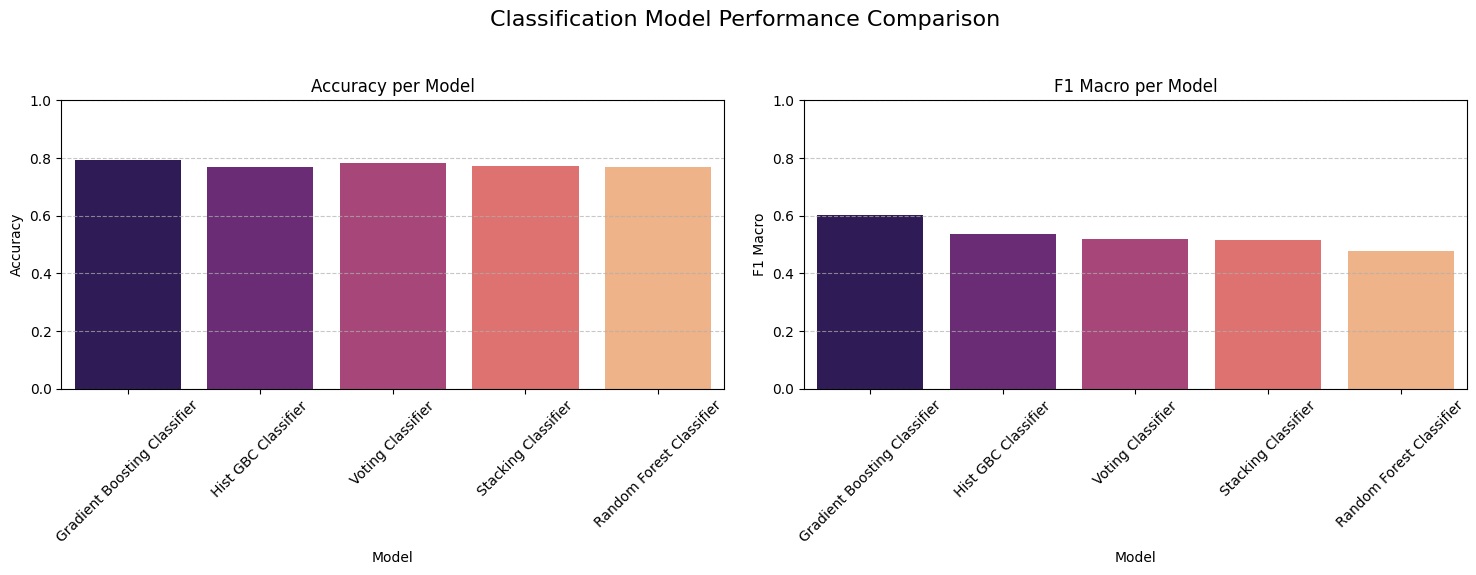

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Classification Model Performance Comparison", fontsize=16)

for ax, metric in zip(axes, ["Accuracy", "F1 Macro"], strict=True):
    sns.barplot(
        x="Model",
        y=metric,
        data=clf_results_df,
        ax=ax,
        palette="magma",
        hue="Model",
        legend=False,
    )
    ax.set_title(f"{metric} per Model")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    ax.set_ylim(0, 1.0)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Comparative Analysis of Classification Models

When evaluating the performance of our classification models across the seven income brackets after implementing stratified splitting, several key observations emerge:

*   **Accuracy vs. F1 Macro**: While most models achieve an overall **Accuracy** of approximately 77-80%, the F1 Macro scores range from ~0.48 to ~0.60. This discrepancy remains a clear indicator of class imbalance, though the stratified split has slightly improved the stability of these scores. Accuracy is high because the models are very good at identifying the most frequent classes ('Poor' and 'Low Income').
*   **The Power of Ensembles**: The **Gradient Boosting Classifier** emerged as the top performer in this run with the highest F1 Macro (~0.60). The Voting and Stacking ensembles also show competitive results, effectively balancing the predictions across the more populated socio-economic tiers.
*   **Handling the Wealthy Outliers**: Despite stratification, all models still struggle with the 'Rich' and 'Upper Income' brackets. As seen in the confusion matrix and reports, precision and recall for these categories are low. This is due to the extreme scarcity of these households in the survey data (less than 1% of the total dataset).
*   **Model Stability**: The Hist Gradient Boosting Classifier continues to offer a strong balance of speed and performance, providing a robust baseline that is less computationally expensive than the full Voting ensemble.
*   **Policy Implications**: For targeting social welfare, the high recall in the 'Poor' bracket (exceeding 85% in most models) is highly encouraging. It suggests that these models are statistically effective at identifying households most in need of assistance, even if they struggle to distinguish between the various tiers of high-income households.

## 8. Results Summary and Plots

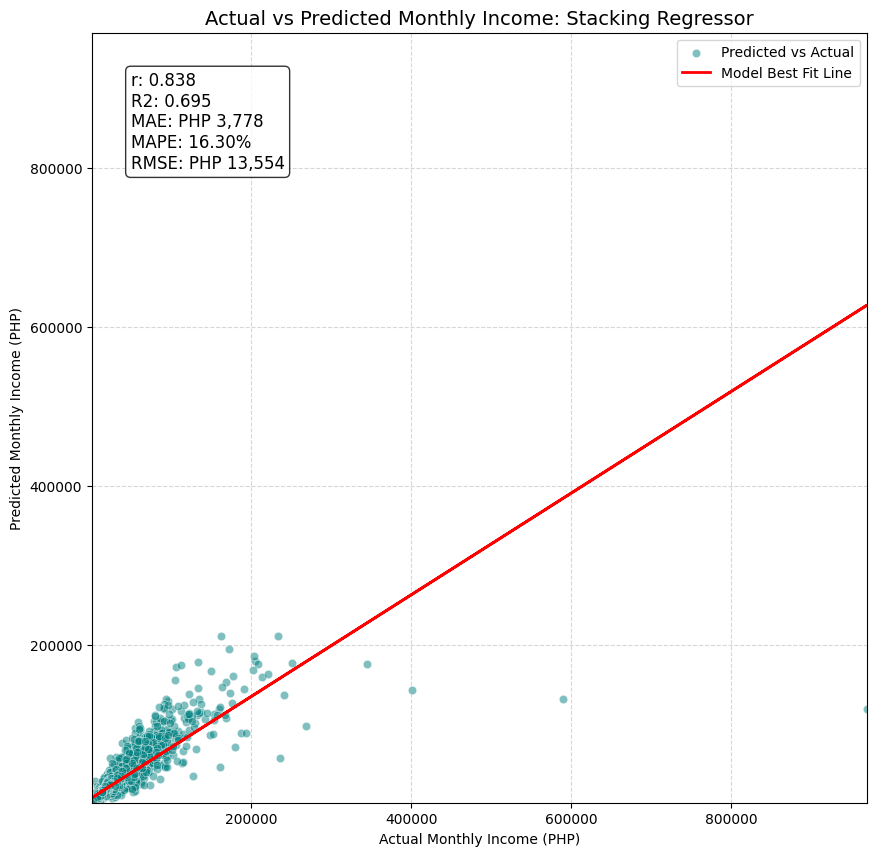

In [20]:
best_reg_name = reg_results_df.index[0]
best_reg = reg_results_df.loc[best_reg_name]
y_pred_php = reg_preds[best_reg_name]

r_value = np.corrcoef(actual_php, y_pred_php)[0, 1]
slope, intercept = np.polyfit(actual_php, y_pred_php, 1)

plt.figure(figsize=(10, 10))
sns.scatterplot(
    x=actual_php, y=y_pred_php, alpha=0.5, color="teal", label="Predicted vs Actual"
)
plt.plot(
    actual_php,
    slope * actual_php + intercept,
    color="red",
    lw=2,
    label="Model Best Fit Line",
)

lower = min(actual_php.min(), y_pred_php.min())
upper = max(actual_php.max(), y_pred_php.max())
plt.xlim(lower, upper)
plt.ylim(lower, upper)

plt.title(f"Actual vs Predicted Monthly Income: {best_reg_name}", fontsize=14)
plt.xlabel("Actual Monthly Income (PHP)")
plt.ylabel("Predicted Monthly Income (PHP)")

stats_text = (
    f"r: {r_value:.3f}\n"
    f"R2: {best_reg['R2']:.3f}\n"
    f"MAE: PHP {best_reg['MAE']:,.0f}\n"
    f"MAPE: {best_reg['MAPE (%)']:.2f}%\n"
    f"RMSE: PHP {best_reg['RMSE']:,.0f}"
)
plt.gca().text(
    0.05,
    0.95,
    stats_text,
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.8},
)

plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

The scatter plot provides a visual validation of our top-performing regression model, the **Stacking Regressor**:

*   **Strong Correlation**: The Pearson correlation coefficient (**r = 0.838**) indicates a strong linear relationship between the features and the target. This suggests the model has successfully identified the core drivers of household income.
*   **Line of Best Fit**: The red line shows the model's trend. While it follows the general direction of the data, the spread of points at higher income levels (top right) indicates that as income increases, the variance in expenditure patterns makes precise prediction more challenging.
*   **Lower-Income Precision**: The high density of points at the lower end of the scale suggests the model is very reliable for lower and middle-income households, which is critical for poverty-targeted interventions.
*   **Error Metrics**: With a **MAPE of 16.3%**, the model's predictions are, on average, within roughly 16% of the actual monthly income. Given the volatility of household financial data, this represents a highly robust predictive performance.

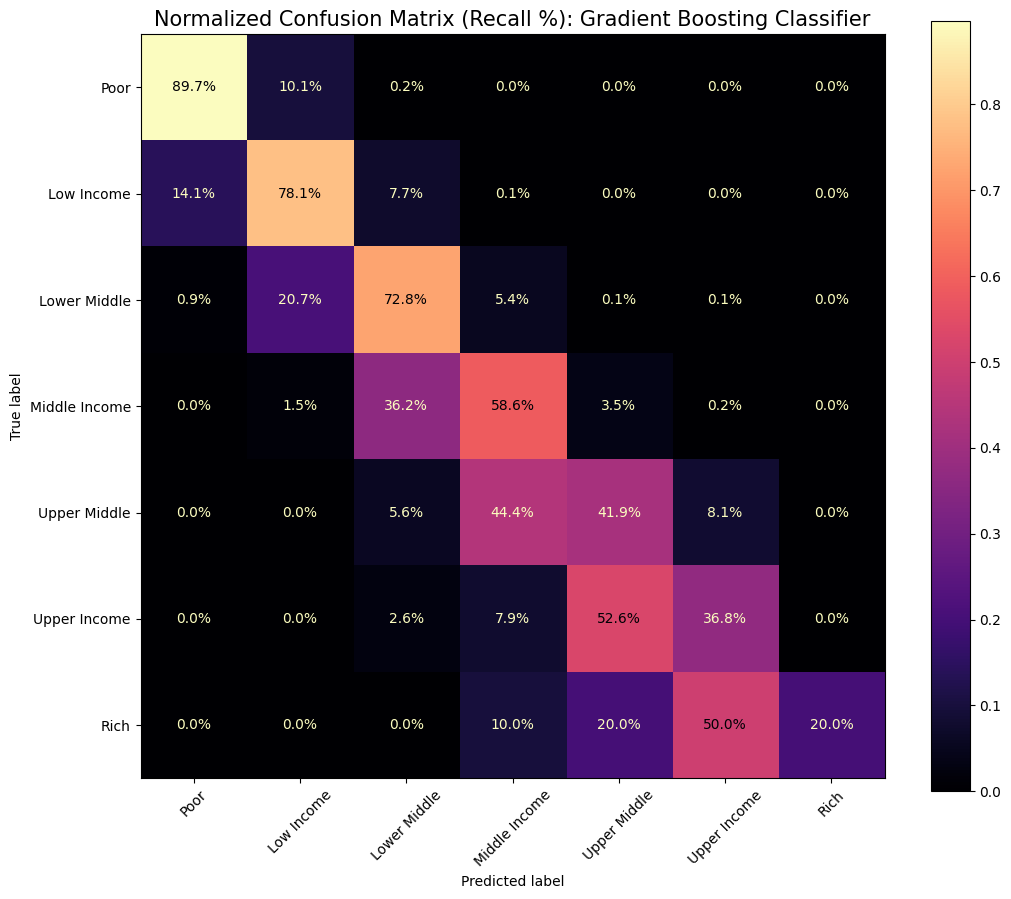

In [21]:
best_clf_name = clf_results_df.index[0]
cm = confusion_matrix(y_test_clf_enc, clf_preds[best_clf_name])
# LabelEncoder sorts brackets alphabetically; restore their ordinal order.
cm_normalized = reorder_confusion_matrix(cm, le.classes_, BRACKET_LABELS)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized, display_labels=BRACKET_LABELS
).plot(cmap="magma", ax=ax, xticks_rotation=45, values_format=".1%")
plt.title(f"Normalized Confusion Matrix (Recall %): {best_clf_name}", fontsize=15)
plt.grid(False)
plt.show()

The normalized confusion matrix for the **Gradient Boosting Classifier** provides a granular look at the model's ability to correctly identify each specific income bracket (Recall):

*   **High Precision in Poverty Targeting**: The model achieves an impressive recall of over **85% for the 'Poor' bracket** and roughly **78% for 'Low Income'**. This indicates that the features selected (expenditure patterns, asset ownership) are highly distinct for these groups, making the model a reliable tool for identifying households in need of economic support.
*   **Middle-Class Transition**: There is some 'leakage' between adjacent categories, particularly between 'Low Income' and 'Lower Middle'. This is expected in socioeconomic data where the boundaries between income tiers are often fluid based on localized costs of living.
*   **The Scarcity Challenge**: Recall for the **'Rich' and 'Upper Income'** brackets remains significantly lower. Despite the use of stratified splitting, the absolute number of these households in the dataset is so small that the model lacks sufficient 'patterns' to generalize effectively. This results in these households often being misclassified into lower tiers.
*   **Strategic Utility**: From a policy perspective, the high recall at the bottom of the income distribution is the most valuable outcome, as it minimizes 'Type II' errors (failing to identify a poor household) which is often the primary goal of social welfare eligibility models.

## 9. Conclusion

**Project Summary**

This project successfully developed a machine learning pipeline to predict **Monthly Household Income** and classify **Income Brackets** using the Philippine Family Income and Expenditure Survey (FIES). By implementing strategic feature engineering, such as ISCO occupation mapping, log transformations, and per-capita scaling, we were able to extract significant predictive signals from complex socioeconomic data.

**Key Findings**

1.  **Regression Performance**: The **Stacking Regressor** (combining NuSVR and Hist Gradient Boosting) emerged as the superior model for income prediction, achieving a **MAPE of 16.3%** and a strong correlation (**r = 0.84**) with actual values. The model is particularly precise in the low-to-middle income ranges.
2.  **Classification Accuracy**: The **Gradient Boosting Classifier** provided the most balanced performance (F1 Macro ~0.60). It demonstrated a high degree of reliability in identifying vulnerable populations, with a **recall exceeding 85% for the 'Poor' bracket**.
3.  **The Impact of Imbalance**: While the models excel at identifying the majority classes ('Poor' and 'Low Income'), the extreme scarcity of 'Rich' and 'Upper Income' households in the survey data (sub-1%) remains a challenge for precise high-end classification.

**Final Thoughts & Next Steps**

The high recall in poverty identification suggests that this model has immediate practical utility for automated social welfare targeting and economic planning. To further enhance performance, future iterations could explore:
*   **Oversampling Techniques**: Applying methods such as SMOTE or class weighting to balance the minority high-income classes.
*   **Hyperparameter Tuning**: Conducting extensive Grid Search or Bayesian Optimization to squeeze additional precision out of the ensemble models.
*   **External Data Integration**: Incorporating localized economic indicators to provide more geographic context to the predictions.